In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
URL = 'https://raw.githubusercontent.com/jakevdp/data-CDCbirths/master/births.csv'
births = pd.read_csv(URL)
births_raw = births.copy()
print(births.head())
print("Shape:", births.shape)
print(births.dtypes)
print("Missing values per column:")
print(births.isna().sum())

   year  month  day gender  births
0  1969      1  1.0      F    4046
1  1969      1  1.0      M    4440
2  1969      1  2.0      F    4454
3  1969      1  2.0      M    4548
4  1969      1  3.0      F    4548
Shape: (15547, 5)
year        int64
month       int64
day       float64
gender        str
births      int64
dtype: object
Missing values per column:
year        0
month       0
day       480
gender      0
births      0
dtype: int64


In [9]:
births_raw['decade'] = 10 * (births_raw['year'] // 10)
decade_gender = births_raw.pivot_table('births', index='decade',
columns='gender', aggfunc='sum')
print(decade_gender)
print("Male > Female in every decade:", (decade_gender['M'] > decade_gender['F']).all())

gender         F         M
decade                    
1960     1753634   1846572
1970    16263075  17121550
1980    18310351  19243452
1990    19479454  20420553
2000    18229309  19106428
Male > Female in every decade: True


In [10]:

summary = pd.DataFrame({
    'M/F ratio': decade_gender['M'] / decade_gender['F'],
    '% male excess': (decade_gender['M'] / decade_gender['F'] - 1) * 100
})
print(summary.round(4))


        M/F ratio  % male excess
decade                          
1960       1.0530         5.2997
1970       1.0528         5.2787
1980       1.0510         5.0960
1990       1.0483         4.8312
2000       1.0481         4.8116


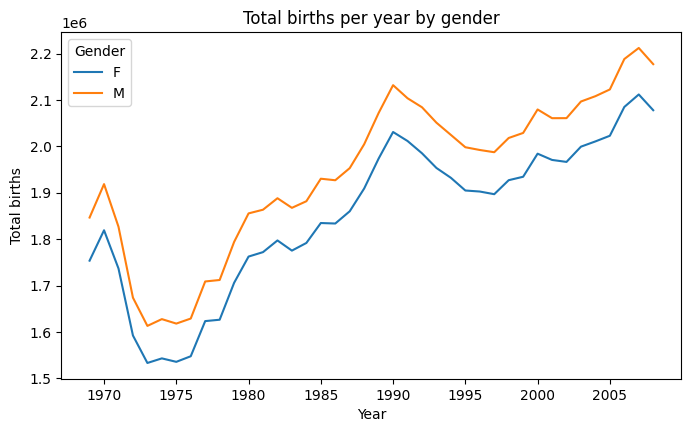

Average yearly gap (M - F): 92568.0
Average gap as % of female births: 5.02


In [11]:
yearly = births_raw.pivot_table('births', index='year', columns='gender', aggfunc='sum')
ax = yearly.plot(figsize=(8, 4.5))
ax.set_xlabel('Year')
ax.set_ylabel('Total births')
ax.set_title('Total births per year by gender')
ax.legend(title='Gender')
plt.savefig('fig_births_per_year.png', dpi=150, bbox_inches='tight')
plt.show()
print("Average yearly gap (M - F):", (yearly['M'] - yearly['F']).mean().round(0))
print("Average gap as % of female births:", ((yearly['M'] / yearly['F'] - 1) * 100).mean().round(2))


In [12]:

Q1, Q2, Q3 = np.percentile(births['births'], [25, 50, 75])
mu = Q2
sig = 0.74 * (Q3 - Q1)
print("Q1 = ",Q1)
print("median = ",mu)
print("Q3 = ",Q3)
print(f"mu = {mu}, sigma = {sig:.2f}")
print(f"Accepted range: {mu - 5*sig:.1f} to {mu + 5*sig:.1f}")

Q1 =  4358.0
median =  4814.0
Q3 =  5289.5
mu = 4814.0, sigma = 689.31
Accepted range: 1367.5 to 8260.5


In [13]:
n_before = len(births)
births = births.query('(births > @mu - 5 * @sig) & (births < @mu + 5 * @sig)').copy()
print('Rows before:', n_before)
print('Rows after :', len(births))
print('Rows removed:', n_before - len(births))

Rows before: 15547
Rows after : 14610
Rows removed: 937


In [14]:
births['day'] = births['day'].astype(int)
print(births.dtypes)
print('Missing values left:', births.isna().sum().sum())

year      int64
month     int64
day       int64
gender      str
births    int64
dtype: object
Missing values left: 0


In [15]:
births.index = pd.to_datetime(births[['year', 'month', 'day']])
births['dayofweek'] = births.index.dayofweek
births['decade'] = 10 * (births['year'] // 10)
print(births.head())
print('Date range:', births.index.min().date(), 'to', births.index.max().date())

            year  month  day gender  births  dayofweek  decade
1969-01-01  1969      1    1      F    4046          2    1960
1969-01-01  1969      1    1      M    4440          2    1960
1969-01-02  1969      1    2      F    4454          3    1960
1969-01-02  1969      1    2      M    4548          3    1960
1969-01-03  1969      1    3      F    4548          4    1960
Date range: 1969-01-01 to 1988-12-31


decade       1960    1970    1980
dayofweek                        
0          5063.8  4689.1  5276.9
1          5286.1  4885.3  5503.8
2          5074.6  4750.4  5367.6
3          4978.3  4696.9  5333.5
4          5107.9  4782.1  5393.1
5          4651.1  4207.8  4483.9
6          4342.3  3979.3  4308.1


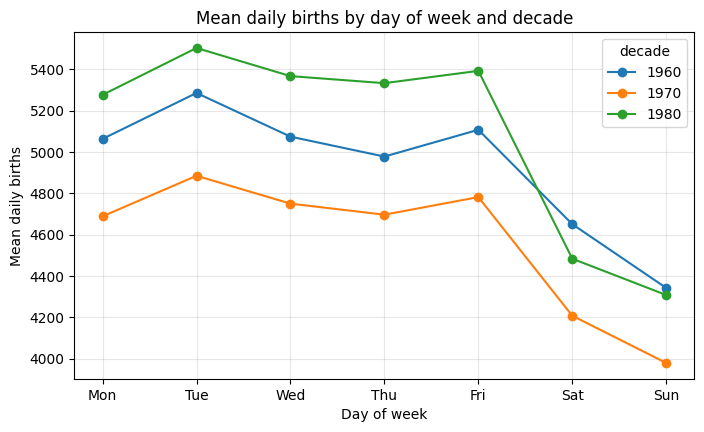

In [16]:
by_weekday = births.pivot_table('births', index='dayofweek', columns='decade', aggfunc='mean')
print(by_weekday.round(1))

ax = by_weekday.plot(figsize=(8, 4.5), marker='o')
ax.set_xticks(range(7))
ax.set_xticklabels(['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun'])
ax.set_xlabel('Day of week')
ax.set_ylabel('Mean daily births')
ax.set_title('Mean daily births by day of week and decade')
ax.grid(alpha=0.3)
plt.show()

In [17]:
births_by_date = births.pivot_table('births', index=['month', 'day'], aggfunc='mean')
print(births_by_date.head())

dates = births_by_date.index.to_frame(index=False)
dates['year'] = 2012          # leap year, so Feb 29 is a valid date
births_by_date.index = pd.to_datetime(dates[['year', 'month', 'day']])
print(births_by_date.head())
print('Number of calendar dates:', len(births_by_date))

             births
month day          
1     1    4009.225
      2    4247.400
      3    4500.900
      4    4571.350
      5    4603.625
              births
2012-01-01  4009.225
2012-01-02  4247.400
2012-01-03  4500.900
2012-01-04  4571.350
2012-01-05  4603.625
Number of calendar dates: 366


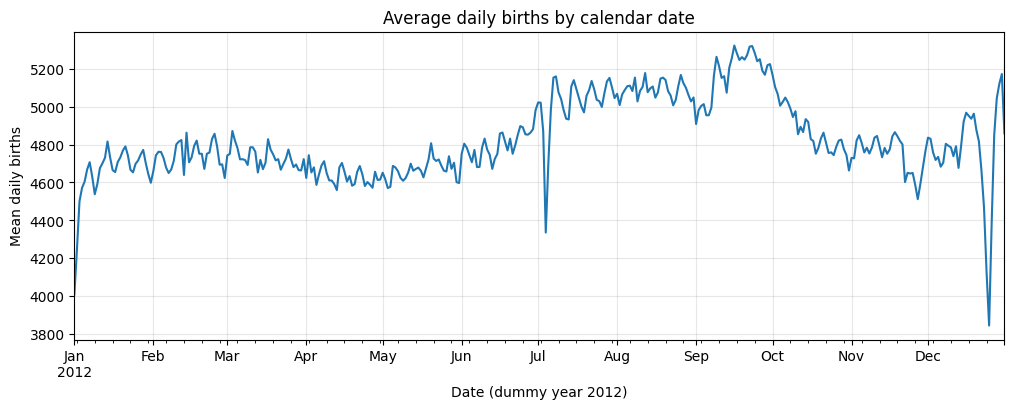

In [18]:
fig, ax = plt.subplots(figsize=(12, 4))
births_by_date.plot(ax=ax, legend=False)
ax.set_xlabel('Date (dummy year 2012)')
ax.set_ylabel('Mean daily births')
ax.set_title('Average daily births by calendar date')
ax.grid(alpha=0.3)
plt.show()

In [19]:
print(births_by_date['births'].nsmallest(10).round(1))


2012-12-25    3844.4
2012-01-01    4009.2
2012-12-24    4126.2
2012-01-02    4247.4
2012-07-04    4335.3
2012-12-26    4383.5
2012-12-23    4466.7
2012-01-03    4500.9
2012-11-27    4511.6
2012-01-09    4537.8
Name: births, dtype: float64


In [20]:
by_group = births_raw.groupby(['decade', 'gender'])['births'].sum().unstack()
print(by_group)
print('Identical to pivot table:', by_group.equals(decade_gender))
pd.testing.assert_frame_equal(by_group, decade_gender, check_names=False)

gender         F         M
decade                    
1960     1753634   1846572
1970    16263075  17121550
1980    18310351  19243452
1990    19479454  20420553
2000    18229309  19106428
Identical to pivot table: True


In [22]:
t_pivot = %timeit -o births_raw.pivot_table('births', index='decade', columns='gender', aggfunc='sum')

10.8 ms ± 403 μs per loop (mean ± std. dev. of 7 runs, 100 loops each)


In [23]:
t_group = %timeit -o births_raw.groupby(['decade', 'gender'])['births'].sum().unstack()

5.46 ms ± 405 μs per loop (mean ± std. dev. of 7 runs, 100 loops each)


In [25]:
timing = pd.DataFrame({
    'Method': ['pivot_table', 'groupby + unstack'],
    'Mean time (ms)': [t_pivot.average * 1000, t_group.average * 1000],
    'Std dev (ms)': [t_pivot.stdev * 1000, t_group.stdev * 1000],
}).round(3)
timing['Relative speed'] = (timing['Mean time (ms)'] / timing['Mean time (ms)'].min()).round(2)
print(timing.to_string(index=False))

           Method  Mean time (ms)  Std dev (ms)  Relative speed
      pivot_table          10.830         0.403            1.99
groupby + unstack           5.455         0.405            1.00


            mean births               holiday
2012-12-25       3844.4         Christmas Day
2012-01-01       4009.2        New Year's Day
2012-12-24       4126.2         Christmas Eve
2012-01-02       4247.4  Day after New Year's
2012-07-04       4335.3      Independence Day


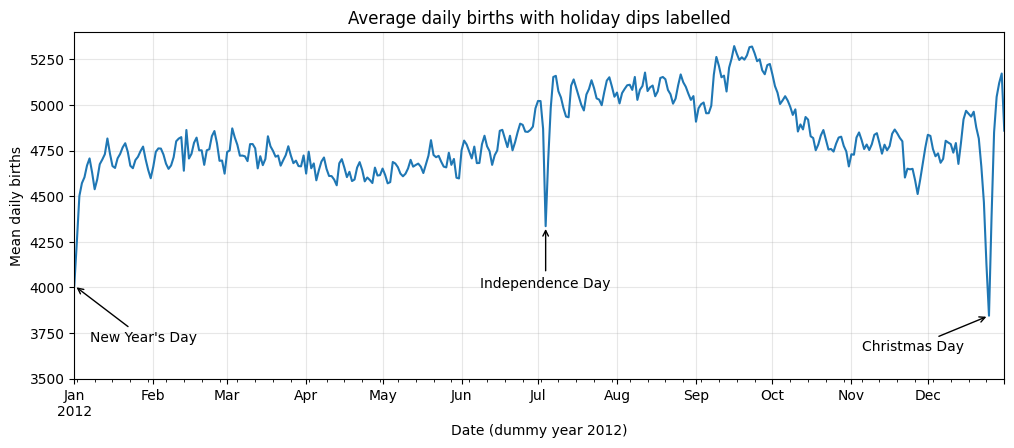

In [26]:
holidays = {(1, 1): "New Year's Day", (1, 2): "Day after New Year's",
            (7, 4): 'Independence Day', (12, 25): 'Christmas Day',
            (12, 24): 'Christmas Eve'}

lowest5 = births_by_date['births'].nsmallest(5).to_frame('mean births').round(1)
lowest5['holiday'] = [holidays.get((d.month, d.day), 'no fixed-date holiday')
                      for d in lowest5.index]
print(lowest5)

s = births_by_date['births']
fig, ax = plt.subplots(figsize=(12, 4.5))
s.plot(ax=ax)
for (m, d), name, text_pos in [((1, 1), "New Year's Day", (pd.Timestamp(2012, 1, 28), 3700)),
                               ((7, 4), 'Independence Day', (pd.Timestamp(2012, 7, 4), 4000)),
                               ((12, 25), 'Christmas Day', (pd.Timestamp(2012, 11, 25), 3650))]:
    ts = pd.Timestamp(2012, m, d)
    ax.annotate(name, xy=(ts, s[ts]), xytext=text_pos,
                arrowprops=dict(arrowstyle='->'), ha='center')
ax.set_ylim(3500, 5400)
ax.set_xlabel('Date (dummy year 2012)')
ax.set_ylabel('Mean daily births')
ax.set_title('Average daily births with holiday dips labelled')
ax.grid(alpha=0.3)
plt.show()